# 04 - Feature exploration

**Aim:** explore the 11 non-composition features used by our SVM and relate their sequence profiles and class distributions to their biological rationale.

We prepared this supplement to [04 - SVM method](04_svm_method.ipynb) using the training proteins only. We kept the feature definitions and settings from that notebook. We compared the sequence profiles and per-protein feature distributions between the two classes.

**Materials**
- `04 - Methods - SVM.pdf` (slides 30–34: composition, other scales and SP architecture).
- `04_feature_extraction_hydrophobicity.ipynb` (A.1–A.2 and A.5: profiles; B.1 and B.3: plots; B.4: summaries).
- `04_svm_method.ipynb` (0.2, 1.2 and 2.2–2.6: loading, settings and feature functions).
- `02c_data_analysis.ipynb` (sections 2 and 5: composition; plotting conventions).
- [Feature choices and literature](../docs/04_feature_candidates.md).

**Status:** figures and observations completed. The expanded summary in 1.7 still needs its displayed output refreshed.

## Scope and composition reference

We covered all 11 non-composition columns: two KD summaries, charge balance, two alpha-helix summaries, two TM-tendency summaries and four project extensions, in the SVM extractor's order.

For composition, we referred to [02c section 5](02c_data_analysis.ipynb#5.-N-terminal-composition:-exploratory-extension). Its comparison pools residues in the first 70 positions, while the SVM uses per-protein first-n fractions. We kept that exploration as context rather than repeating it here.

We retained the current feature settings and used the training split, keeping benchmarking reserved. Any feature redesign based on these plots would need selection within training folds to preserve an independent evaluation.


## 0. Load training proteins

We followed the main notebook's relative paths and Conda `LB2` environment. Only metadata rows assigned to training enter this analysis.

In [ ]:
# Imports and relative paths follow 04_svm_method.ipynb, section 0.1.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

input_dir = Path("../data/prepared")
figure_dir = Path("../results/figures/04/feature_exploration")
table_dir = Path("../results/tables/04/feature_exploration")
figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

# Class order and colors follow 02c_data_analysis.ipynb.
class_order = ["Positive", "Negative"]
class_palette = {"Positive": "C0", "Negative": "C1"}
sns.set_theme(style="whitegrid")

In [ ]:
# Reader reused from 04_svm_method.ipynb, section 0.2 (originally 03, section 1.1).
def read_fasta(fasta_path):
    sequences = {}
    with open(fasta_path, encoding="utf-8") as fasta_in:
        for line in fasta_in:
            line = line.strip()
            if line.startswith(">"):
                accession = line[1:].split()[0]
                sequences[accession] = ""
            elif line:
                sequences[accession] += line
    return sequences

positive_data = pd.read_csv(input_dir / "positive_dataset.tsv", sep="\t", dtype={"cv_fold": "Int64"})
negative_data = pd.read_csv(input_dir / "negative_dataset.tsv", sep="\t", dtype={"cv_fold": "Int64"})
positive_data = positive_data[positive_data["split"] == "training"].copy()
negative_data = negative_data[negative_data["split"] == "training"].copy()

positive_sequences = read_fasta(input_dir / "positive_dataset.fasta")
negative_sequences = read_fasta(input_dir / "negative_dataset.fasta")
positive_data["sequence"] = positive_data["accession"].map(positive_sequences)
negative_data["sequence"] = negative_data["accession"].map(negative_sequences)
positive_data["protein_class"] = "Positive"
negative_data["protein_class"] = "Negative"
training_data = pd.concat([positive_data, negative_data], ignore_index=True)

print("Training proteins:", len(training_data))
training_data.groupby("protein_class").size().reindex(class_order).rename("proteins").to_frame()

Training proteins: 8146


,proteins
protein_class,
Positive,881
Negative,7265


## 1. Reuse the feature definitions

We reused the settings and feature functions from `04_svm_method.ipynb` so this supplement can run on its own. Their comments retain the references to the main notebook and class examples.

### 1.1 Scales and fixed settings

We retained first-40 profiles, KD and alpha-helix windows of 5, the TM window of 19 and the first-5 charge proxy. The external scale values and limitations are documented in the feature notes.

In [ ]:
# Scale lookup follows setup and A.1 in 04_feature_extraction_hydrophobicity.ipynb.
from Bio.SeqUtils.ProtParamData import kd

hydropathy_scale = kd
# Shared alphabet for our composition extractor; not supplied by the hydropathy example.
aa_alphabet = list("ACDEFGHIKLMNPQRSTVWY")

# Region and window follow the starting example on slide 34 of 04 - Methods - SVM.pdf.
hydropathy_length = 40
hydropathy_window = 5

# Fixed region for our charge proxy in 2.3; an extension of SVM slide 32.
charge_length = 5

# Fixed project settings for the regional extensions in 2.6; not class defaults.
hydropathy_threshold = 0.0
postpeak_length = 5
postpeak_small_residues = "AGS"
cleavage_small_residues = "ACGST"

# Additional scale profiles follow SVM slides 31 and 34; window sizes are our choices.
propensity_length = 40
alpha_helix_window = 5
tm_tendency_window = 19

# Published values from ProtScale; scale lookup follows A.1 in
# 04_feature_extraction_hydrophobicity.ipynb, replacing its KD dictionary.
# Chou-Fasman: https://web.expasy.org/protscale/pscale/alpha-helixFasman.html
alpha_helix_scale = {
    "A": 1.42, "C": 0.70, "D": 1.01, "E": 1.51, "F": 1.13,
    "G": 0.57, "H": 1.00, "I": 1.08, "K": 1.16, "L": 1.21,
    "M": 1.45, "N": 0.67, "P": 0.57, "Q": 1.11, "R": 0.98,
    "S": 0.77, "T": 0.83, "V": 1.06, "W": 1.08, "Y": 0.69,
}
# Zhao-London: https://web.expasy.org/protscale/pscale/Transmembranetendency.html
tm_tendency_scale = {
    "A": 0.38, "C": -0.30, "D": -3.27, "E": -2.90, "F": 1.98,
    "G": -0.19, "H": -1.44, "I": 1.97, "K": -3.46, "L": 1.82,
    "M": 1.40, "N": -1.62, "P": -1.44, "Q": -1.84, "R": -2.57,
    "S": -0.53, "T": -0.32, "V": 1.46, "W": 1.53, "Y": 0.49,
}

### 1.2 Hydropathy profile and summaries

We reused the complete-window loop and KD wrappers from main notebook 2.2, based on class example A.1–A.2/A.5 and B.4. Unknown positions stay in place; windows average their known scale values. Entirely missing windows remain NaN.

In [ ]:
# Reused from 04_svm_method.ipynb, section 2.2.
hydropathy_feature_names = [
    f"hydropathy_max_w{hydropathy_window}",
    f"hydropathy_profile_mean_w{hydropathy_window}",
]


# This function combines A.1 (residue values) and A.2 (window_profile) in
# 04_feature_extraction_hydrophobicity.ipynb, with the unknown-residue policy from A.5.
def scale_profile(sequence, scale, window, length):
    """Complete-window means for a residue scale, retaining unknown positions."""
    # Similar to A.1: look up one scale value per residue, retaining unknown positions.
    values = [
        scale.get(residue, np.nan)
        for residue in sequence[:length]
    ]
    profile = []
    # Similar to window_profile in A.2: slide only complete windows along the sequence.
    for start in range(len(values) - window + 1):
        # Adapted from A.5: average known residues, without shrinking the end windows.
        window_values = [
            value
            for value in values[start : start + window]
            if not np.isnan(value)
        ]
        profile.append(float(np.mean(window_values)) if window_values else np.nan)
    return profile


# KD wrapper around the shared A.2-style loop; existing feature functions keep
# the same interface and fixed settings from SVM slide 34.
def hydropathy_profile(sequence):
    """Complete-window KD profile over the fixed N-terminal region."""
    return scale_profile(sequence, hydropathy_scale, hydropathy_window, hydropathy_length)


# This function follows profile aggregation in B.4 of
# 04_feature_extraction_hydrophobicity.ipynb and the max/mean pair on SVM slide 34.
def hydropathy_features(sequence):
    """Maximum and mean of the non-missing window values of the profile."""
    profile = [value for value in hydropathy_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in hydropathy_feature_names}
    return dict(zip(hydropathy_feature_names, [max(profile), float(np.mean(profile))]))

### 1.3 N-terminal charge

The first-5 charge proxy uses K/R as +1 and D/E as −1, divided by canonical residue count; other canonical residues, including H, score zero.

**Source:** `04_svm_method.ipynb`, section 2.3.

In [ ]:
# Reused from 04_svm_method.ipynb, section 2.3.
charge_feature_names = [f"nterminal_charge_first{charge_length}"]


# Project extension: residue counting like 2.1, motivated by SVM slide 32 and
# Guo et al. (2018); no equivalent charge function in the class notebooks.
def nterminal_charge(sequence):
    """Mean K/R (+1) and D/E (-1) proxy over canonical residues in the first 5 positions."""
    residues = [residue for residue in sequence[:charge_length] if residue in aa_alphabet]
    if not residues:
        return np.nan
    positive = sum(residue in "KR" for residue in residues)
    negative = sum(residue in "DE" for residue in residues)
    return (positive - negative) / len(residues)


# Project grouping, like the feature dictionary in B.4 of
# 04_feature_extraction_hydrophobicity.ipynb; charge is proposed on SVM slide 31.
def charge_features(sequence):
    """N-terminal charge proxy as a named feature dictionary."""
    return {charge_feature_names[0]: nterminal_charge(sequence)}

### 1.4 Alpha-helix propensity

We reused the Chou–Fasman profile and its mean/maximum summaries. 

**Source:** `04_svm_method.ipynb`, section 2.4.

In [ ]:
# Reused from 04_svm_method.ipynb, section 2.4.
alpha_helix_feature_names = [
    f"alpha_helix_profile_mean_w{alpha_helix_window}",
    f"alpha_helix_max_w{alpha_helix_window}",
]


# Same A.2-style profile as 2.2, with another scale as proposed on SVM slide 34.
# The window loop comes from 04_feature_extraction_hydrophobicity.ipynb.
def alpha_helix_profile(sequence):
    """Complete-window alpha-helix propensity profile over the fixed N-terminus."""
    return scale_profile(sequence, alpha_helix_scale, alpha_helix_window, propensity_length)


# Same profile aggregation as 2.2 and B.4 of
# 04_feature_extraction_hydrophobicity.ipynb.
def alpha_helix_features(sequence):
    """Mean and maximum of the non-missing alpha-helix window values."""
    profile = [value for value in alpha_helix_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in alpha_helix_feature_names}
    return dict(zip(alpha_helix_feature_names, [float(np.mean(profile)), max(profile)]))

### 1.5 Transmembrane tendency

We reused the Zhao–London profile and its mean/maximum summaries. 

**Source:** `04_svm_method.ipynb`, section 2.5.

In [ ]:
# Reused from 04_svm_method.ipynb, section 2.5.
tm_tendency_feature_names = [
    f"tm_tendency_profile_mean_w{tm_tendency_window}",
    f"tm_tendency_max_w{tm_tendency_window}",
]


# Same A.2-style profile as 2.2, with another scale as proposed on SVM slide 34.
# The window loop comes from 04_feature_extraction_hydrophobicity.ipynb.
def tm_tendency_profile(sequence):
    """Complete-window transmembrane-tendency profile over the fixed N-terminus."""
    return scale_profile(sequence, tm_tendency_scale, tm_tendency_window, propensity_length)


# Same profile aggregation as 2.2 and B.4 of
# 04_feature_extraction_hydrophobicity.ipynb.
def tm_tendency_features(sequence):
    """Mean and maximum of the non-missing transmembrane window values."""
    profile = [value for value in tm_tendency_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in tm_tendency_feature_names}
    return dict(zip(tm_tendency_feature_names, [float(np.mean(profile)), max(profile)]))

### 1.6 Additional sequence descriptors

We retained peak position, positive-KD-run extent, post-peak A/G/S fraction and −3/−1 motif support, including the main notebook’s missing-value and empty-region conventions.

**Source:** `04_svm_method.ipynb`, section 2.6.

In [ ]:
# Reused from 04_svm_method.ipynb, section 2.6.
additional_feature_names = [
    "hydropathy_peak_position",
    "hydrophobic_stretch_length",
    "postpeak_small_fraction",
    "cleavage_motif_score",
]


# Project extension of the profile summaries in B.4 of
# 04_feature_extraction_hydrophobicity.ipynb; 2.2 supplies the A.2-style profile.
def hydropathy_peak_position(sequence):
    """1-based center of the first maximum window, preserving unknown positions."""
    profile = hydropathy_profile(sequence)
    if not profile or np.all(np.isnan(profile)):
        return np.nan
    peak_start = int(np.nanargmax(profile))
    return peak_start + hydropathy_window // 2 + 1


# Project extension of B.4 in 04_feature_extraction_hydrophobicity.ipynb:
# summarize contiguous windows rather than just their maximum or mean.
def hydrophobic_stretch_length(sequence):
    """Residue span covered by the longest run of above-threshold KD windows."""
    profile = hydropathy_profile(sequence)
    if not profile or np.all(np.isnan(profile)):
        return np.nan
    current_run = 0
    longest_run = 0
    for value in profile:
        if value > hydropathy_threshold:
            current_run += 1
            longest_run = max(longest_run, current_run)
        else:
            current_run = 0
    return longest_run + hydropathy_window - 1 if longest_run else 0


# Project counting extension, like composition in 2.1; regional idea from
# Imai et al. (2011), not an exact function from the class notebooks.
def postpeak_small_fraction(sequence):
    """A/G/S fraction just after the maximum window, within the fixed N-terminus."""
    peak = hydropathy_peak_position(sequence)
    if np.isnan(peak):
        return np.nan
    window_end = int(peak) + hydropathy_window // 2
    region = sequence[window_end : min(window_end + postpeak_length, hydropathy_length)]
    if not region:
        return 0.0
    residues = [residue for residue in region if residue in aa_alphabet]
    if not residues:
        return np.nan
    return sum(residue in postpeak_small_residues for residue in residues) / len(residues)


# Project motif scan: like score_sequence in section 3 of 03_von_heijne_method.ipynb,
# but only fixed -3/-1 membership scores, without its trained PSWM.
def cleavage_motif_score(sequence):
    """Best small-residue support at -3/-1 among sequence-derived candidate bonds."""
    peak = hydropathy_peak_position(sequence)
    if np.isnan(peak):
        return np.nan
    first_site = max(int(peak) + hydropathy_window // 2, 3)
    last_site = min(hydropathy_length, len(sequence) - 1)
    scores = []
    for site in range(first_site, last_site + 1):
        residues = [sequence[site - 3], sequence[site - 1]]
        if all(residue in aa_alphabet for residue in residues):
            scores.append(sum(residue in cleavage_small_residues for residue in residues) / 2)
    return max(scores) if scores else 0.0


# Project feature dictionary, like B.4 of
# 04_feature_extraction_hydrophobicity.ipynb, collecting our four extensions.
def additional_features(sequence):
    """Peak position, hydrophobic extent and downstream context features."""
    return {
        additional_feature_names[0]: hydropathy_peak_position(sequence),
        additional_feature_names[1]: hydrophobic_stretch_length(sequence),
        additional_feature_names[2]: postpeak_small_fraction(sequence),
        additional_feature_names[3]: cleavage_motif_score(sequence),
    }

### 1.7 Build the exploratory feature table

We assembled one row per training accession. The summary reports count, mean, sample standard deviation (`std`, ddof = 1), minimum, quartiles, median and maximum for each feature and class. Standard deviation describes variation between proteins; quartiles describe the middle half of each distribution.

Missing values are excluded separately for each feature, and `count` reports the number of contributing proteins. The expanded statistics were saved in the TSV; the displayed output below still needs refreshing.


In [ ]:
# Assembly follows extract_features in 04_svm_method.ipynb, section 2.7,
# retaining only the non-composition groups explored here.
feature_names = (
    hydropathy_feature_names + charge_feature_names + alpha_helix_feature_names
    + tm_tendency_feature_names + additional_feature_names
)
records = []
for sequence in tqdm(training_data["sequence"], desc="Extracting features", unit="protein"):
    record = {}
    record.update(hydropathy_features(sequence))
    record.update(charge_features(sequence))
    record.update(alpha_helix_features(sequence))
    record.update(tm_tendency_features(sequence))
    record.update(additional_features(sequence))
    records.append(record)

feature_data = pd.DataFrame(records, index=pd.Index(training_data["accession"], name="accession"))
feature_data = feature_data[feature_names]
feature_data["protein_class"] = training_data.set_index("accession")["protein_class"]

long_features = feature_data.reset_index().melt(
    id_vars=["accession", "protein_class"], value_vars=feature_names,
    var_name="feature", value_name="value"
)
feature_summary = long_features.groupby(["feature", "protein_class"])["value"].describe()
feature_summary = feature_summary.rename(
    columns={"25%": "q25", "50%": "median", "75%": "q75"}
).reset_index()
summary_path = table_dir / "1_7_training_feature_summary.tsv"
feature_summary.to_csv(summary_path, sep="\t", index=False)
print("Table saved in:", summary_path)
feature_summary

## 2. Compare profiles along the N-terminus

We adapted the profile plots in class example B.1/B.3 to compare training classes. Lines show the median window value at each position; shaded bands show the 25th–75th percentile range across proteins.

The x-axis marks 1-based window centers: 3–38 for w = 5 and 10–31 for w = 19. Each scale has its own y-axis. Positive means SP and Negative means NO_SP.


In [ ]:
# Profiles reuse the main notebook's functions; center coordinates follow
# A.2 in 04_feature_extraction_hydrophobicity.ipynb.
profile_settings = [
    ("Kyte-Doolittle", hydropathy_profile, hydropathy_window),
    ("Alpha-helix propensity", alpha_helix_profile, alpha_helix_window),
    ("Transmembrane tendency", tm_tendency_profile, tm_tendency_window),
]
profile_tables = {}
for name, profile_function, window in profile_settings:
    profiles = [
        profile_function(sequence)
        for sequence in tqdm(training_data["sequence"], desc=name, unit="protein")
    ]
    profile_table = pd.DataFrame(profiles, index=training_data["accession"])
    profile_table.columns = np.arange(profile_table.shape[1]) + window // 2 + 1
    profile_tables[name] = profile_table

Transmembrane tendency: 100%|██████████| 8146/8146 [00:03<00:00, 2423.95protein/s]


Plot saved in: ../results/figures/04/feature_exploration/2_1_training_scale_profiles.pdf


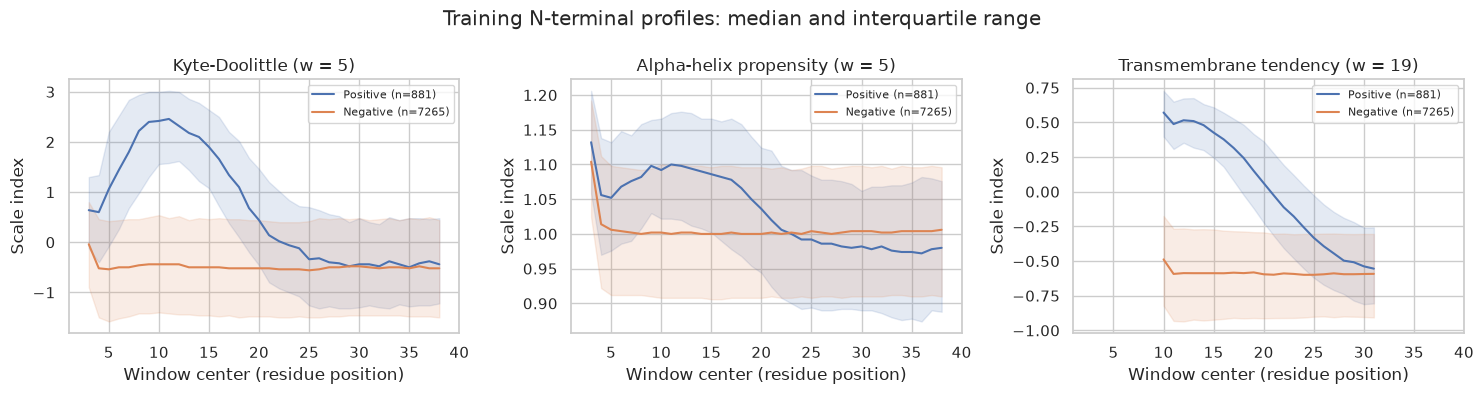

In [ ]:
# Matplotlib profile lines follow B.1/B.3 in the class hydrophobicity notebook.
# Class median/IQR summaries are our descriptive extension; PDF saving follows 02c.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, (name, profile_function, window) in zip(axes, profile_settings):
    profile_table = profile_tables[name]
    for protein_class in class_order:
        accessions = training_data.loc[
            training_data["protein_class"] == protein_class, "accession"
        ]
        values = profile_table.loc[accessions]
        ax.plot(
            values.columns, values.median(), color=class_palette[protein_class],
            label=f"{protein_class} (n={len(values)})"
        )
        ax.fill_between(
            values.columns, values.quantile(0.25), values.quantile(0.75),
            color=class_palette[protein_class], alpha=0.15
        )
    ax.set_title(f"{name} (w = {window})")
    ax.set_xlabel("Window center (residue position)")
    ax.set_ylabel("Scale index")
    ax.set_xlim(1, hydropathy_length)
    ax.legend(fontsize=8)
fig.suptitle("Training N-terminal profiles: median and interquartile range")
fig.tight_layout()
profile_path = figure_dir / "2_1_training_scale_profiles.pdf"
fig.savefig(profile_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", profile_path)
plt.show()

**Observations.** We observed a clear early hydrophobic region in the positive class: the median KD profile peaked around positions 10–11 and declined further downstream. The negative median stayed below zero across most positions. The positive TM-tendency profile showed a similar early elevation and decline. These patterns suggest that the intensity, position and extent of the hydrophobic region contain information about the class. The TM scale describes sequence propensity; its elevation alone does not establish a transmembrane segment.

The alpha-helix profile showed a smaller positive-class elevation around positions 10–15, with considerable overlap between the shaded ranges. The classes became more similar further downstream, so averaging the full region may dilute this local difference. This profile still showed a class-related pattern, even though its separation was weaker than for KD and TM tendency. The shaded ranges describe variation between proteins.


## 3. Compare per-protein feature distributions

We normalized each histogram within its class so the larger negative class does not dominate the comparison. Both classes use common bin edges for each feature, and values retain their original units.

### 3.1 Profile summaries

We compared all six profile summaries: KD maximum/mean, alpha-helix mean/maximum and TM-tendency mean/maximum. As illustrated in class example B.4, maxima describe local peaks while means summarize the full profile.


Plot saved in: ../results/figures/04/feature_exploration/3_1_training_profile_summaries.pdf


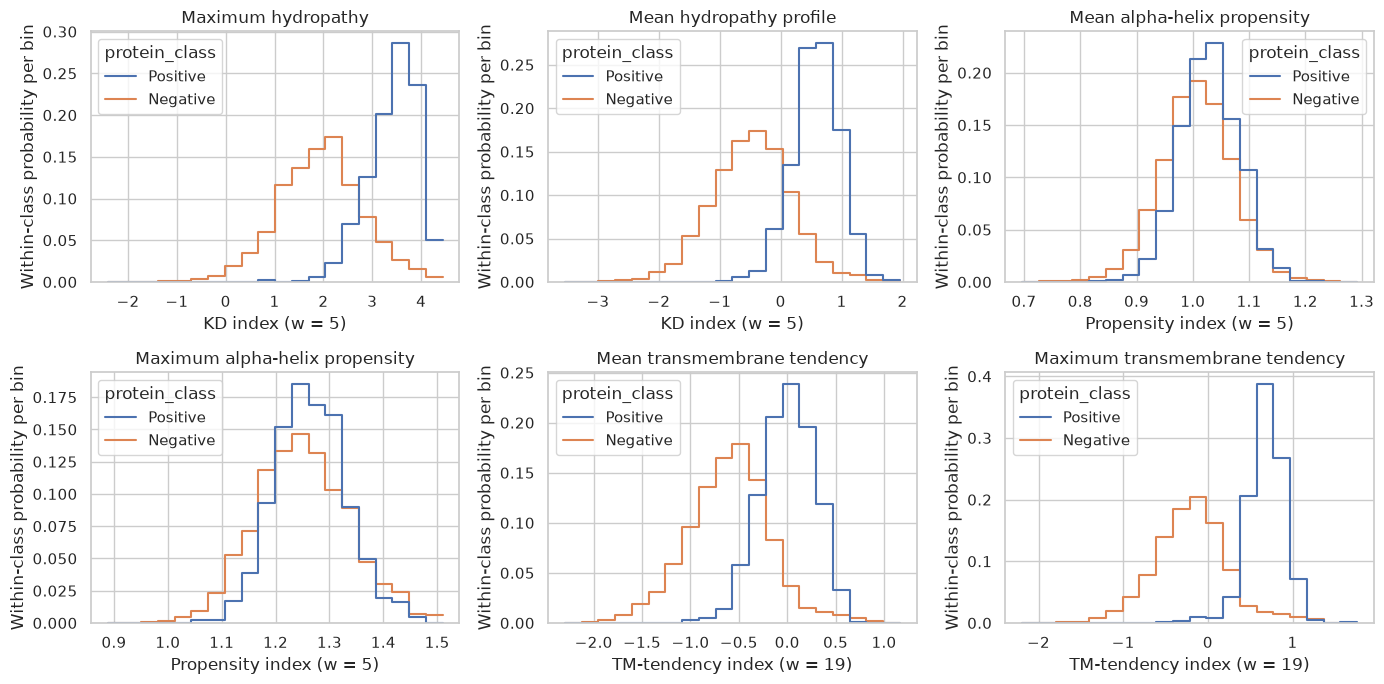

In [ ]:
# Project plot labels, matching the feature names and definitions in the main notebook.
feature_labels = {
    hydropathy_feature_names[0]: ("Maximum hydropathy", "KD index (w = 5)"),
    hydropathy_feature_names[1]: ("Mean hydropathy profile", "KD index (w = 5)"),
    charge_feature_names[0]: ("N-terminal charge balance", "Charge proxy (first 5 positions)"),
    alpha_helix_feature_names[0]: ("Mean alpha-helix propensity", "Propensity index (w = 5)"),
    alpha_helix_feature_names[1]: ("Maximum alpha-helix propensity", "Propensity index (w = 5)"),
    tm_tendency_feature_names[0]: ("Mean transmembrane tendency", "TM-tendency index (w = 19)"),
    tm_tendency_feature_names[1]: ("Maximum transmembrane tendency", "TM-tendency index (w = 19)"),
    additional_feature_names[0]: ("Hydropathy peak position", "Window center (1-based)"),
    additional_feature_names[1]: ("Hydrophobic stretch extent", "Residue span of positive KD windows"),
    additional_feature_names[2]: ("Post-peak small-residue fraction", "A/G/S fraction"),
    additional_feature_names[3]: ("Cleavage-motif compatibility", "Motif support score"),
}


# Class histograms follow the length distributions in 02c, section 1.
# Common edges and separate class normalization allow a descriptive comparison.
def plot_feature_distributions(names, filename):
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, feature in zip(axes.flat, names):
        if feature == "cleavage_motif_score":
            bins = np.array([-0.25, 0.25, 0.75, 1.25])
        elif feature == "hydropathy_peak_position":
            bins = np.arange(2.5, hydropathy_length, 1)
        else:
            bins = np.histogram_bin_edges(feature_data[feature].dropna(), bins=20)
        sns.histplot(
            data=feature_data, x=feature, hue="protein_class", hue_order=class_order,
            palette=class_palette, bins=bins, stat="probability", common_norm=False,
            element="step", fill=False, ax=ax
        )
        title, xlabel = feature_labels[feature]
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Within-class probability per bin")
    for ax in axes.flat[len(names):]:
        ax.set_visible(False)
    fig.tight_layout()
    path = figure_dir / filename
    fig.savefig(path, format="pdf", bbox_inches="tight")
    print("Plot saved in:", path)
    plt.show()


summary_features = hydropathy_feature_names + alpha_helix_feature_names + tm_tendency_feature_names
plot_feature_distributions(summary_features, "3_1_training_profile_summaries.pdf")

**Observations.** Both KD summaries were informative about the class: positives tended to have a stronger local hydrophobic peak and a higher mean profile. Median KD maxima were 3.48 in positives and 1.94 in negatives; median means were 0.59 and −0.47. The two summaries describe peak intensity and overall hydrophobicity, although they may share information.

The TM summaries also showed clear shifts, especially the maximum (median 0.70 versus −0.19); median profile means were 0.02 and −0.58. These distributions support retaining both as candidate predictors. The plots do not establish how much information they add beyond KD.

Alpha-helix propensity showed weaker individual separation. Median means were 1.029 and 1.007, and median maxima were 1.262 and 1.250, for positives and negatives. The mean showed a modest shift, while the maxima were particularly similar. These features may still help in combination with other descriptors, but that added value remains to be tested.


### 3.2 Charge and additional sequence features

We compared charge balance, peak position, hydrophobic extent, post-peak A/G/S fraction and cleavage-motif support. Charge uses the first 5 positions, whereas the composition comparison in 02c uses 70 residues.

Region definitions and the treatment of missing values follow main notebook sections 2.3 and 2.6 and the [feature notes](../docs/04_feature_candidates.md).


Plot saved in: ../results/figures/04/feature_exploration/3_2_training_charge_and_context.pdf


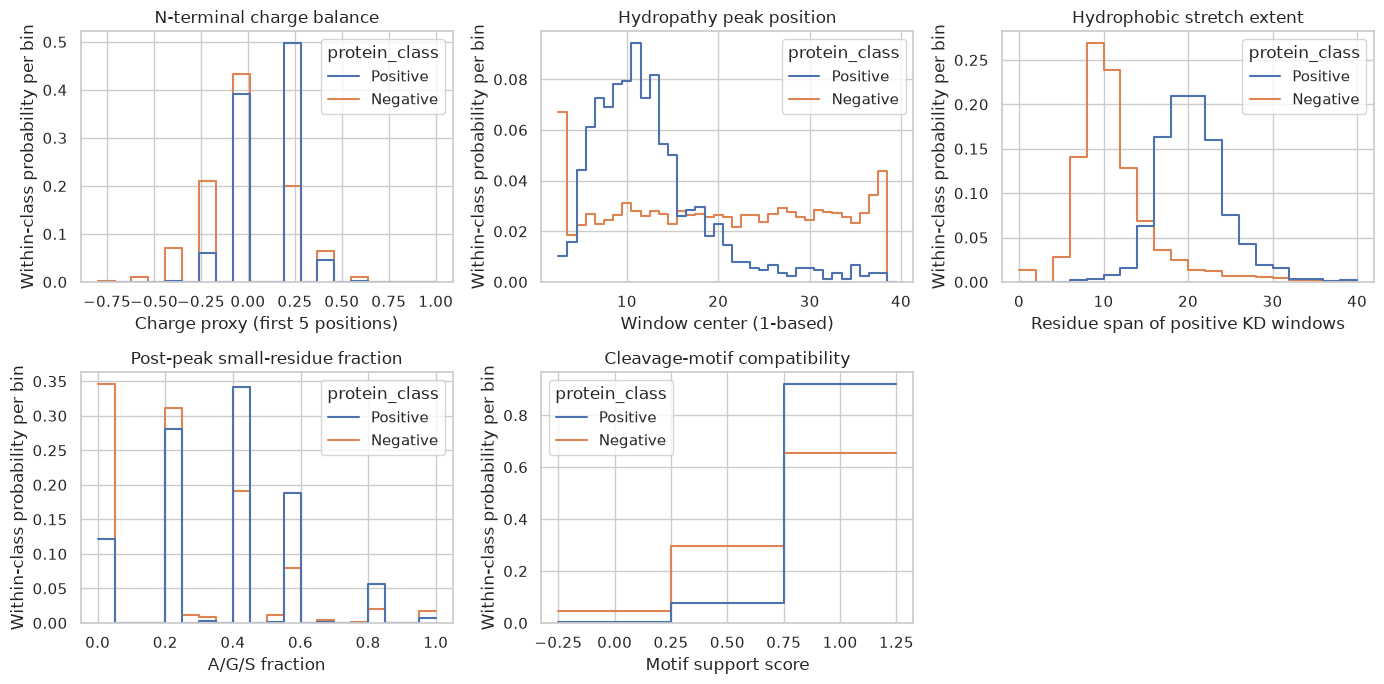

In [ ]:
# Same normalized class histograms as 3.1; all remaining non-composition features.
regional_features = charge_feature_names + additional_feature_names
plot_feature_distributions(regional_features, "3_2_training_charge_and_context.pdf")

**Observations.** Charge balance provided information about the class: positives were shifted towards positive values (median 0.2 versus 0), although the classes shared many values. Hydropathy peaks were earlier and more concentrated in positives (median position 11 versus 20), making peak location another informative descriptor.

Hydrophobic extent showed a clear difference (median 20 versus 10 residues). This feature measures the span covered by consecutive positive KD windows, so the values describe our sequence-based indicator rather than annotated h-region lengths. Together, peak location and extent added descriptions of where the hydrophobic region occurred and how far it extended.

Post-peak A/G/S fraction was higher in positives (median 0.4 versus 0.2), suggesting potential information despite substantial overlap. However, the function returns 0 when no region remains after the peak within the first 40 residues. Later peaks in negatives could therefore contribute to the difference; these zeros can represent either no available region or an observed region without A/G/S.

Cleavage-motif support was informative despite a median of 1 in both classes: about 91.9% of positives and 65.6% of negatives scored 1. The high negative frequency limited its specificity on its own. We took the best candidate motif, and an earlier peak allowed more positions to be searched, so the score may also reflect search-region length. It describes motif compatibility somewhere in that region, rather than identifying the actual cleavage site.


## 4. Overall observations

We found evidence of class-related information across the feature groups, with different degrees of separation. KD and TM maxima/means and hydrophobic extent showed the clearest differences. Peak position and charge added positional and charge information. Alpha-helix propensity showed weaker differences, especially its maximum; its usefulness in combination remains an open question.

Post-peak A/G/S fraction and motif support also showed class differences, but their interpretation depended on the region definitions. A/G/S zeros could indicate an unavailable region, and motif support may partly reflect the number of candidate sites searched. These features remained candidates with useful distributional differences, rather than demonstrated gains in prediction.

Positives had lower standard deviations for all 11 features, showing less dispersion in these measurements. This was compatible with greater heterogeneity among negatives, without establishing its biological cause. The taxonomic differences described in 02c may also contribute to the observed patterns.

An informative feature may overlap with other descriptors or receive a low RF rank. We retained all candidates for training-fold selection. Nested CV will evaluate the complete classification procedure; establishing the added predictive value of a particular feature or group would require a comparison with and without it.
